In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

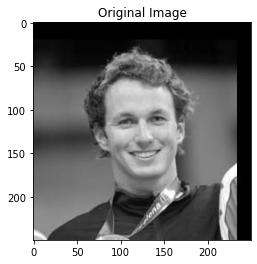

In [2]:
# Load image and convert to grayscale
file_path = 'Face1.jpg'
img = Image.open(file_path).convert('L')  # 'L' for grayscale

# Display original image
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.show()

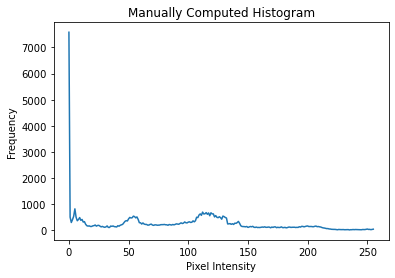

In [3]:
# (a) Manually Compute Histogram
image_array = np.array(img)
hist_manual = np.zeros(256)

for row in image_array:
    for pixel in row:
        hist_manual[pixel] += 1

# Plot
plt.plot(hist_manual)
plt.title('Manually Computed Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

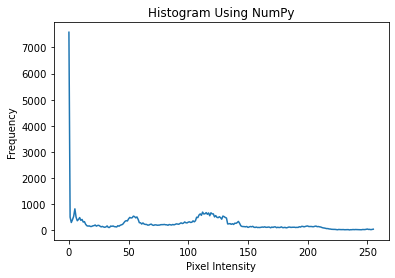

In [4]:
# (b) Use NumPy to Compute the Color Histogram
hist_np, bins = np.histogram(image_array, bins=256, range=(0, 255))

# Plot
plt.plot(hist_np)
plt.title('Histogram Using NumPy')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

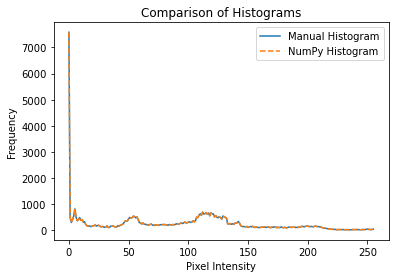

In [5]:
# (c) Compare both
plt.plot(hist_manual, label='Manual Histogram')
plt.plot(hist_np, label='NumPy Histogram', linestyle='dashed')
plt.title('Comparison of Histograms')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

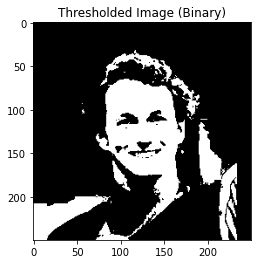

In [6]:
# (d) Apply Thresholding
threshold = 128
binary_image = np.where(image_array > threshold, 255, 0)
binary_image_pil = Image.fromarray(np.uint8(binary_image))

# Display the thresholded image
plt.imshow(binary_image_pil, cmap='gray')
plt.title('Thresholded Image (Binary)')
plt.show()

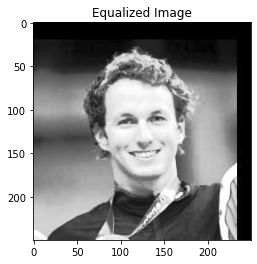

In [7]:
# (e) Histogram Equalization
def histogram_equalization(image_array):
    # Flatten image to 1D, bins = 256, and range = [0,256]
    hist, bins = np.histogram(image_array.flatten(), 256, [0, 256])
    
    # CDF is cumulative sum of the histogram
    cdf = hist.cumsum()
    
    # Multiply CDF by (255 / cdf[-1]) to normalize it so that the maximum CDF value is 255.
    cdf_normalized = cdf * (255 / cdf[-1])
    
    # 'np.interp' maps pixel intensities from original image to new intensity values defined by normalized CDF.
    # Flatten original image and perform the mapping
    equalized_image = np.interp(image_array.flatten(), bins[:-1], cdf_normalized)
    
    # Reshape the flattened 1D array into the original 2D shape and return
    return equalized_image.reshape(image_array.shape), cdf_normalized

equalized_image, cdf = histogram_equalization(image_array)
equalized_image_pil = Image.fromarray(np.uint8(equalized_image))

# Display the equalized image
plt.imshow(equalized_image_pil, cmap='gray')
plt.title('Equalized Image')
plt.show()

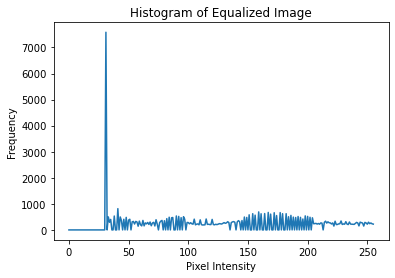

In [8]:
# Plot the histogram of the equalized image
equalized_hist, bins = np.histogram(equalized_image.flatten(), bins=256, range=(0, 255))
plt.plot(equalized_hist)
plt.title('Histogram of Equalized Image')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()